# Гипотеза: сотрудники с низкой зарплатой увольняются чаще

## Цель: проверить связь между уровнем заработной платы и текучестью персонала.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Загружаем подготовленный датасет V4
df = pd.read_csv("V4_Employee_cleaned.csv")

### Анализ распределения заработной платы по должностям
Цель: изучить различия в уровне заработной платы между должностями и определить подход к формированию сопоставимых зарплатных когорт.

,employees,salary_min,salary_median,salary_mean,salary_max
jobrole,,,,,
Recruiter,24,20583,30854.0,37648.0,70703
Sales Representative,83,20650,36101.0,40656.0,97794
Software Engineer,294,20418,42704.0,51967.0,439641
Data Scientist,261,20387,44057.0,56079.0,455643
HR Executive,28,41745,89376.0,94362.0,201564
Machine Learning Engineer,146,39456,98598.0,130165.0,366078
Sales Executive,327,37035,100314.0,117196.0,350525
Senior Software Engineer,132,36012,106898.0,126161.0,380248
Engineering Manager,75,115110,292500.0,286259.0,539998


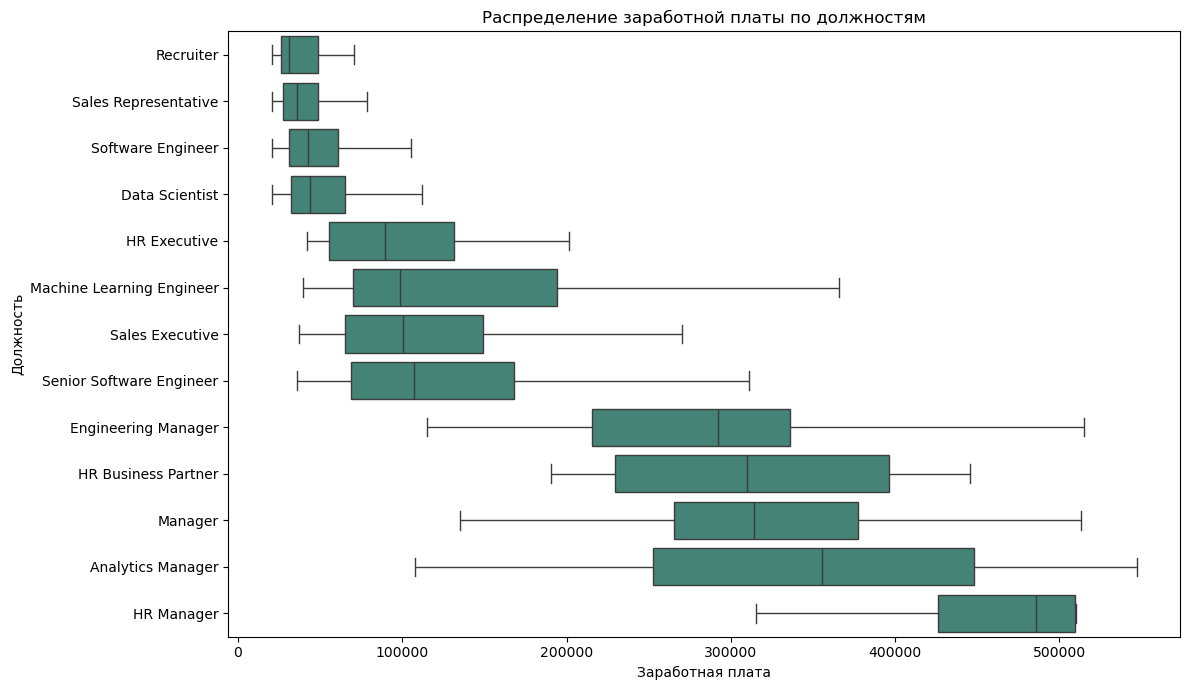

In [3]:
# Статистика зарплат по должностям
role_salary = (
    df.groupby("jobrole")
    .agg(
        employees=("employeeid", "nunique"),
        salary_min=("salary", "min"),
        salary_median=("salary", "median"),
        salary_mean=("salary", "mean"),
        salary_max=("salary", "max")
    )
    .sort_values("salary_median")
    .round(0)
)

display(role_salary)

# Визуализация
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="salary",
    y="jobrole",
    order=role_salary.index,
    color="#3A8D7B",
    showfliers=False
)

plt.title("Распределение заработной платы по должностям")
plt.xlabel("Заработная плата")
plt.ylabel("Должность")
plt.tight_layout()
plt.show()

Итог: анализ выявил существенные различия в зарплатах между должностями и значительный разброс внутри отдельных позиций. 
Сравнение сотрудников только по абсолютной зарплате может искажать результаты. Для дальнейшей проверки гипотезы принято решение формировать зарплатные когорты отдельно внутри каждой должности, используя относительный уровень оплаты труда.

### Формирование зарплатных когорт внутри должностей
Метод: с помощью groupby() и pd.qcut() сотрудники каждой должности распределяются на три примерно равные по численности когорты:

Low — нижняя треть зарплат внутри должности.

Medium — средняя треть зарплат.

High — верхняя треть зарплат.

In [4]:
# Создаём зарплатные когорты внутри должностей
df["salary_role_group"] = (
    df.groupby("jobrole")["salary"]
      .transform(
          lambda x: pd.qcut(
              x.rank(method="first"),
              q=3,
              labels=["Low", "Medium", "High"]
          )
      )
)

# Проверяем распределение сотрудников
cohort_summary = (
    df.groupby(["jobrole", "salary_role_group"], observed=True)
      .agg(
          employees=("employeeid", "count"),
          median_salary=("salary", "median")
      )
      .reset_index()
)

display(cohort_summary)

,jobrole,salary_role_group,employees,median_salary
0,Analytics Manager,Low,17,230945.0
1,Analytics Manager,Medium,17,350101.0
2,Analytics Manager,High,18,473864.5
3,Data Scientist,Low,87,29449.0
4,Data Scientist,Medium,87,44057.0
5,Data Scientist,High,87,83590.0
6,Engineering Manager,Low,25,190198.0
7,Engineering Manager,Medium,25,292500.0
8,Engineering Manager,High,25,365504.0
9,HR Business Partner,Low,2,204830.5


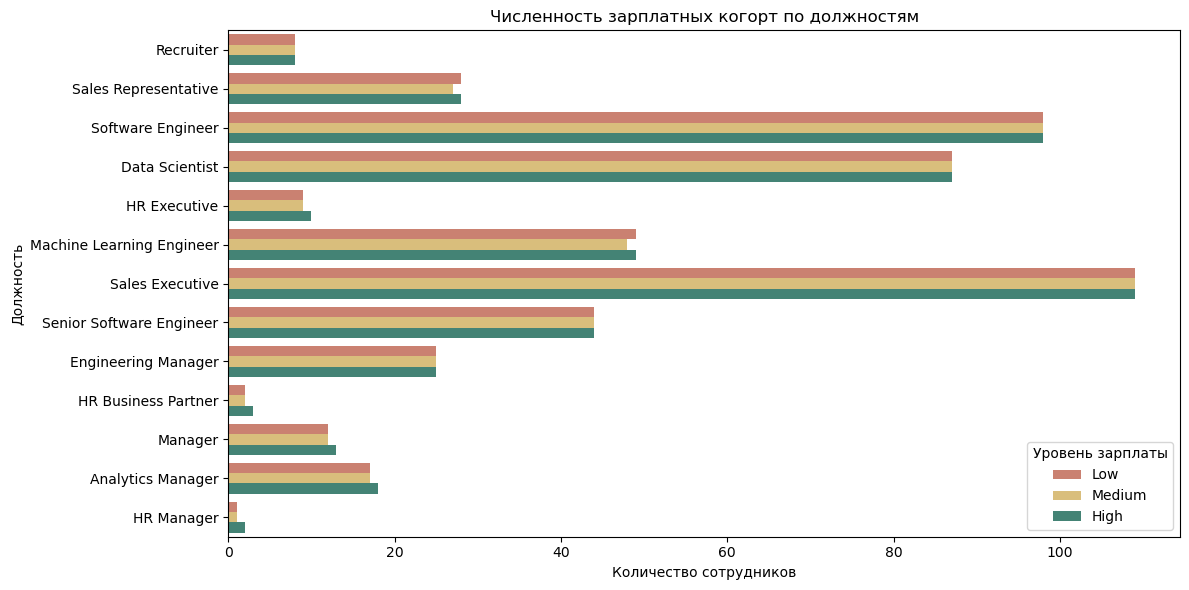

In [5]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="jobrole",
    hue="salary_role_group",
    hue_order=["Low", "Medium", "High"],
    palette=["#D97762", "#E8C56D", "#3A8D7B"],
    order=role_salary.index
)

plt.title("Численность зарплатных когорт по должностям")
plt.xlabel("Количество сотрудников")
plt.ylabel("Должность")
plt.legend(title="Уровень зарплаты")
plt.tight_layout()
plt.show()

### Анализ текучести по зарплатным когортам
Для каждой зарплатной когорты рассчтываем общее количество сотрудников, число уволившихся и долю увольнений. Показатель текучести определяется как отношение количества уволившихся к общей численности сотрудников соответствующей когорты.

,employees,left_company,attrition_rate
salary_role_group,,,
Low,489,82,16.77
Medium,487,81,16.63
High,494,74,14.98


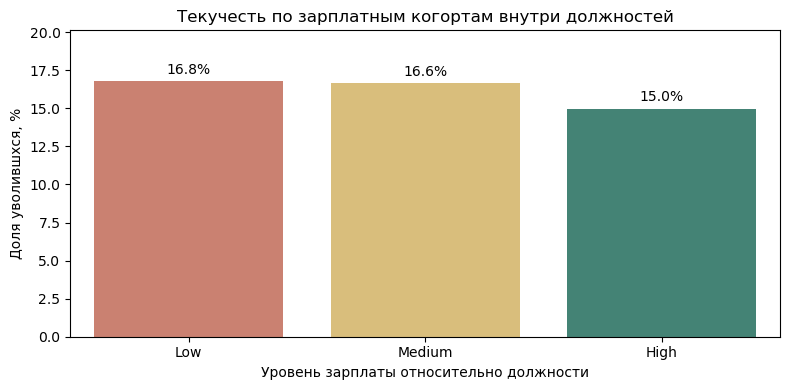

In [11]:
cohort_order = ["Low", "Medium", "High"]

# Рассчтываем текучесть по зарплатным когортам
attrition_by_salary = (
    df.groupby("salary_role_group", observed=True)
      .agg(
          employees=("employeeid", "count"),
          left_company=("attrition_flag", "sum"),
          attrition_rate=("attrition_flag", "mean")
      )
      .reindex(cohort_order)
)

attrition_by_salary["attrition_rate"] *= 100

display(attrition_by_salary.round(2))

# Визуализация
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    data=attrition_by_salary.reset_index(),
    x="salary_role_group",
    y="attrition_rate",
    order=cohort_order,
    hue="salary_role_group",
    palette=["#D97762", "#E8C56D", "#3A8D7B"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Текучесть по зарплатным когортам внутри должностей")
plt.xlabel("Уровень зарплаты относительно должности")
plt.ylabel("Доля уволившхся, %")
plt.ylim(0, max(attrition_by_salary["attrition_rate"]) * 1.2)
plt.tight_layout()
plt.show()

Выявлена слабая тенденция к более высокой текучести среди сотрудников с относительно низкой зарплатой. Однако на данном этапе нельзя утверждать, что различия статистически значимы.

### Анализ текучести по зарплатным когортам в разрезе должностей
Для каждой должности и зарплатной когорты (Low, Medium, High) рассчитываем численность сотрудников, количество увольнений и долю уволившихся.

salary_role_group,Low,Medium,High,"Low - High, п.п."
jobrole,,,,
Analytics Manager,5.88,5.88,5.56,0.33
Data Scientist,22.99,26.44,21.84,1.15
Engineering Manager,0.00,4.00,4.00,-4.00
Machine Learning Engineer,8.16,6.25,6.12,2.04
Manager,0.00,8.33,7.69,-7.69
Sales Executive,13.76,16.51,22.02,-8.26
Sales Representative,50.00,51.85,17.86,32.14
Senior Software Engineer,4.55,4.55,11.36,-6.82
Software Engineer,22.45,14.29,11.22,11.22


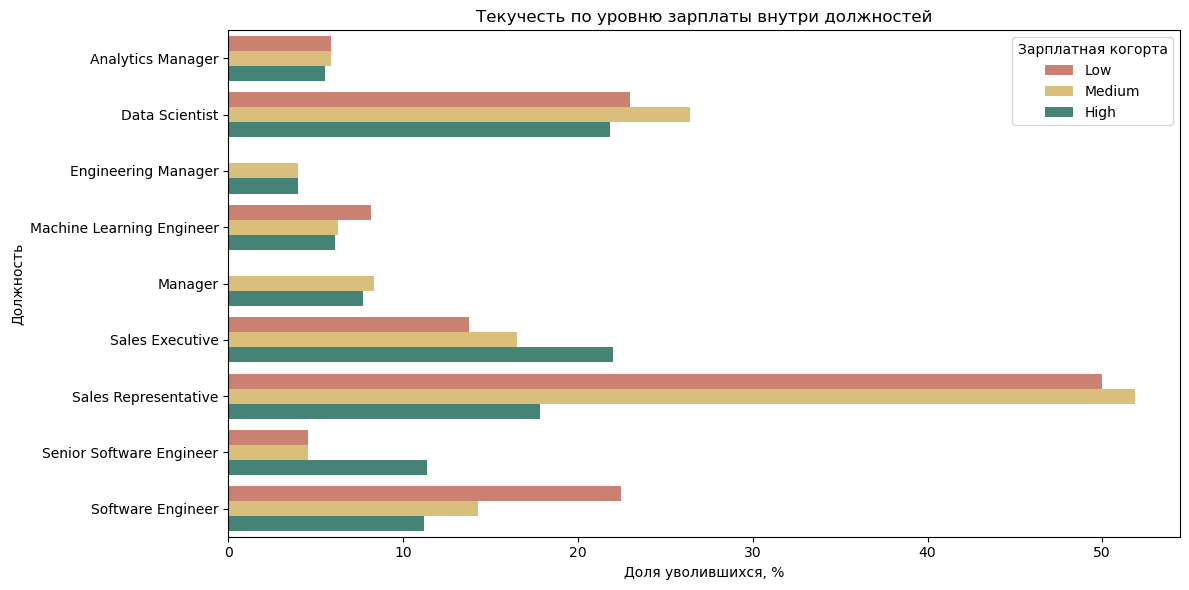

In [12]:
# Текучесть по должностям и зарплатным когортам
role_attrition = (
    df.groupby(["jobrole", "salary_role_group"], observed=True)
      .agg(
          employees=("employeeid", "count"),
          left_company=("attrition_flag", "sum"),
          attrition_rate=("attrition_flag", "mean")
      )
      .reset_index()
)

role_attrition["attrition_rate"] *= 100

# Оставляем должности >= 30 сотрудниками
valid_roles = df["jobrole"].value_counts()
valid_roles = valid_roles[valid_roles >= 30].index

role_attrition_filtered = role_attrition[
    role_attrition["jobrole"].isin(valid_roles)
]

# Сводная таблица
role_pivot = role_attrition_filtered.pivot(
    index="jobrole",
    columns="salary_role_group",
    values="attrition_rate"
)

role_pivot["Low - High, п.п."] = (
    role_pivot["Low"] - role_pivot["High"]
)

display(role_pivot.round(2))

# Визуализация
plt.figure(figsize=(12, 6))

sns.barplot(
    data=role_attrition_filtered,
    y="jobrole",
    x="attrition_rate",
    hue="salary_role_group",
    hue_order=["Low", "Medium", "High"],
    palette=["#D97762", "#E8C56D", "#3A8D7B"]
)

plt.title("Текучесть по уровню зарплаты внутри должностей")
plt.xlabel("Доля уволившихся, %")
plt.ylabel("Должность")
plt.legend(title="Зарплатная когорта")
plt.tight_layout()
plt.show()

Связь между относительным уровнем зарплаты и текучестью неоднородна. Для некоторых должностей наблюдается более высокая текучесть среди низкооплачиваемых сотрудников, тогда как для других зависимость обратная.

### Проверка статистической значимости связи зарплаты и текучести
используем критерий независимости χ² (хи-квадрат Пирсона), поскольку сравниваем две категориальные переменные: зарплатную когорту (Low, Medium, High) и факт увольнения (0 — работает, 1 — уволился).

H₀: зарплатная когорта и факт увольнения независимы.
H₁: между зарплатной когортой и фактом увольнения существует статистическая связь.

Уровень значимости — α = 0,05. Если p-value меньше 0,05, отвергаем H₀.

In [8]:
from scipy.stats import chi2_contingency

# Таблица сопряжённости
contingency = pd.crosstab(
    df["salary_role_group"],
    df["attrition_flag"]
).reindex(["Low", "Medium", "High"])

display(contingency)

# Критерий хи-квадрат
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Chi-square: {chi2:.4f}")
print(f"p-value: {p_value:.6f}")
print(f"Степени свободы: {dof}")

if p_value < 0.05:
    print("Есть статистически значимая связь между зарплатной когортой и увольнением.")
else:
    print("Статистически значимая связь не обнаружена.")

attrition_flag,0,1
salary_role_group,,
Low,407,82
Medium,406,81
High,420,74


Chi-square: 0.7218
p-value: 0.697057
Степени свободы: 2
Статистически значимая связь не обнаружена.


Статистически значимая связь между зарплатной когортой и увольнением сотрудников в общей выборке не обнаружена. Оснований отвергнуть нулевую гипотезу нет.
Несмотря на небольшую разницу в текучести между Low (16,77%) и High (14,98%), полученных данных недостаточно, чтобы считать её статистически значимой.
При этом общий χ²-тест не позволяет определить наличие значимых различий внутри отдельных должностей. Поэтому следующим этапом проводим отдельные статистические проверки по должностям.

### Проверка статистической значимости различий внутри должностей
Для каждой должности с численностью не менее 30 сотрудников проводим односторонний точный критерий Фишера.

In [14]:

from scipy.stats import fisher_exact

results = []

for role in valid_roles:
    # Берём сотрудников одной должности
    # и только две зарплатные группы
    data = df[
        (df["jobrole"] == role) &
        (df["salary_role_group"].isin(["Low", "High"]))
    ]

    # Считаем работающих и уволившихся
    table = pd.crosstab(
        data["salary_role_group"],
        data["attrition_flag"]
    ).reindex(index=["Low", "High"], columns=[0, 1], fill_value=0)

    # Проверяем: увольняются ли сотрудники Low чаще High?
    _, p = fisher_exact(
        [[table.loc["Low", 1], table.loc["Low", 0]],
         [table.loc["High", 1], table.loc["High", 0]]],
        alternative="greater"
    )

    # Рассчитываем текучесть
    low = table.loc["Low", 1] / table.loc["Low"].sum() * 100
    high = table.loc["High", 1] / table.loc["High"].sum() * 100

    results.append([role, round(low, 2), round(high, 2),
                    round(low - high, 2), round(p, 4)])

# Выводим результаты
fisher_results = pd.DataFrame(
    results,
    columns=["Должность", "Low, %", "High, %",
             "Разница, п.п.", "p-value"]
)

display(fisher_results.sort_values("p-value"))


,Должность,"Low, %","High, %","Разница, п.п.",p-value
5,Sales Representative,50.00,17.86,32.14,0.0113
1,Software Engineer,22.45,11.22,11.22,0.0276
2,Data Scientist,22.99,21.84,1.15,0.5000
3,Machine Learning Engineer,8.16,6.12,2.04,0.5000
7,Analytics Manager,5.88,5.56,0.33,0.7429
4,Senior Software Engineer,4.55,11.36,-6.82,0.9450
0,Sales Executive,13.76,22.02,-8.26,0.9619
6,Engineering Manager,0.00,4.00,-4.00,1.0000
8,Manager,0.00,7.69,-7.69,1.0000


Результаты указывают на возможную связь низкой зарплаты с повышенной текучестью среди Sales Representative и Software Engineer. 
К другим должностям не относится.